# 5 · State estimation as a lie detector

The Kalman filter's NIS against its chi-square law, three attacks through the filter, and the IEEE
14-bus model. See [Lesson 5](../docs/lessons/05-state-estimation-as-a-lie-detector.md).

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from fdicps import plotting
from fdicps.dual_anomaly_data_generation.parameters import load_sensor_parameters

plotting.use_style()
P = load_sensor_parameters()

mean NIS: 5.033


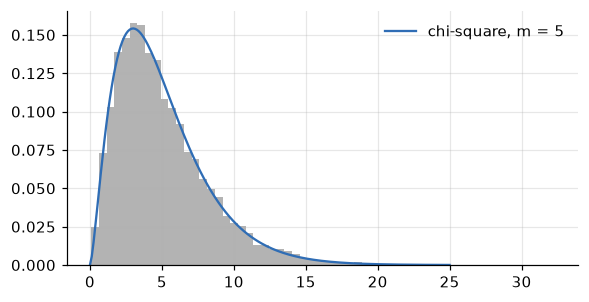

In [2]:
from scipy import stats

from fdicps.cross_sensor_consistency_model.kalman import axis_model, run_filter
from fdicps.dual_anomaly_data_generation.scenarios import generate_dataset

normal = generate_dataset(range(150))
values = normal.values[normal.label == 0]
model = axis_model(P, 1)
nis = run_filter(values, P, model).nis[:, 60:].ravel()
x = np.linspace(0, 25, 200)
fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(nis, bins=60, density=True, color="0.7")
ax.plot(x, stats.chi2.pdf(x, model.m), color=plotting.FAULT_COLOR, label=f"chi-square, m = {model.m}")
ax.legend(frameon=False)
print("mean NIS:", nis.mean().round(3))

In [3]:
from fdicps.adversarial_robustness_analysis.attacks import spoofer_variant
from fdicps.cross_sensor_consistency_model.detection import filter_axes, window_alarm

for reach in ("receivers", "bus", "bus, air data protected"):
    d = np.stack([spoofer_variant(s, reach).values for s in range(4_000_000, 4_000_060)])
    print(f"{reach:26s} detected {window_alarm(filter_axes(d, P), 0.01).mean():.2f}")

receivers                  detected 0.97
bus                        detected 0.00


bus, air data protected    detected 0.50


In [4]:
from fdicps.cross_sensor_consistency_model import ieee14

model14 = ieee14.model()
rng = np.random.default_rng(0)
z = rng.normal(size=model14.m) * model14.sigma
c = rng.normal(scale=0.2, size=model14.n)
print("residual change under a = Hc:", np.abs(model14.residual(z + model14.H @ c) - model14.residual(z)).max())
print("meters to alter, buses 2-14:", ieee14.meters_to_move_one_state())

residual change under a = Hc: 1.6618650899857812e-15
meters to alter, buses 2-14: [9, 5, 11, 9, 9, 7, 3, 9, 5, 5, 5, 7, 5]
